In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector

def tfim_hamiltonian(num_qubits, J=1.0, h=1.0):
    """Transverse-field Ising Hamiltonian on an open chain as a SparsePauliOp."""
    terms = []
    for i in range(num_qubits - 1):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        pauli[i + 1] = "Z"
        terms.append(("".join(reversed(pauli)), -J))
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "X"
        terms.append(("".join(reversed(pauli)), -h))
    return SparsePauliOp.from_list(terms)


def trotter_evolution_circuit(H, num_qubits, dt, n_steps, order=1):
    """Prepare |00..0> and apply n_steps Trotter steps of size dt."""
    if order == 1:
        synth = LieTrotter(reps=1)
    else:
        synth = SuzukiTrotter(order=order, reps=1)
    qc = QuantumCircuit(num_qubits)
    qc.barrier()
    step = PauliEvolutionGate(H, time=dt, synthesis=synth)
    for _ in range(n_steps):
        qc.append(step, range(num_qubits))
    return qc.decompose(reps=2)


def avg_op(num_qubits, p):
    """(1/N) * sum_i P_i for a single-site Pauli letter p."""
    terms = [("".join(p if k == i else "I" for k in reversed(range(num_qubits))), 1.0 / num_qubits)
             for i in range(num_qubits)]
    return SparsePauliOp.from_list(terms)


def trotter_states(H, num_qubits, dt, n_steps, order=1):
    """States after 0, 1, ..., n_steps Trotter steps (time t_n = n*dt)."""
    one_step = trotter_evolution_circuit(H, num_qubits, dt, 1, order)
    sv = Statevector.from_label("0" * num_qubits)
    states = [sv]
    for _ in range(n_steps):
        sv = sv.evolve(one_step)
        states.append(sv)
    return states


def circuit_cost(H, num_qubits, dt, n_steps, order=1):
    """(depth, #CNOT) of the n_steps circuit after transpiling to rz/sx/x/cx."""
    qc = trotter_evolution_circuit(H, num_qubits, dt, n_steps, order)
    tqc = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
    return tqc.depth(), tqc.count_ops().get("cx", 0)

In [ ]:
# [cell 1] Versions and imports
# If needed (once):  %pip install -q "qiskit>=1.2" qiskit-aer qiskit-ibm-runtime scipy matplotlib
import time
import matplotlib.pyplot as plt
from scipy.sparse.linalg import expm_multiply
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeFez
import qiskit, qiskit_aer, qiskit_ibm_runtime, scipy
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__,
      "| ibm-runtime", qiskit_ibm_runtime.__version__, "| scipy", scipy.__version__)

qiskit 2.5.2 | aer 0.17.2 | ibm-runtime 0.50.0 | scipy 1.18.1


In [3]:
# [cell 2] Settings (change QUICK to True first for a fast smoke test)
QUICK  = False
N      = 6 if QUICK else 12     # spins
T      = 2.0                    # final time
NSTEPS = 8                      # Trotter steps -> dt = 0.25 (see cell 4 for the justification)
DT     = T / NSTEPS
KS     = [2, 4, 6, 8]           # noisy points at t = k*DT (add more later if runtime allows)
SCALES = (1, 3)                 # ZNE noise factors (1,3,5 gives a 3-point fit, but costs more)
SHOTS  = 500 if QUICK else 2000
METHOD = "statevector"          # Aer method; alternatives: "matrix_product_state", "density_matrix"
# Depth trick: Mz is identical for 1st and 2nd order here, so Z-basis circuits use the
# cheaper 1st-order formula and only the X-basis (Mx) circuits use 2nd order.
ORDER_FOR = {"Z": 1, "X": 2}

In [4]:
# [cell 3] Exact reference (classical, same N and times)
H = tfim_hamiltonian(N, 1.0, 1.0)
Hs = H.to_matrix(sparse=True).tocsr()
Mz_op, Mx_op = avg_op(N, "Z"), avg_op(N, "X")
Mz_s, Mx_s = Mz_op.to_matrix(sparse=True), Mx_op.to_matrix(sparse=True)
psi0 = np.zeros(2**N, dtype=complex); psi0[0] = 1.0

def expect(M, psi):
    return float(np.real(np.vdot(psi, M @ psi)))

def exact_curve(num):                      # exact states at t = linspace(0, T, num)
    P = expm_multiply(-1j * Hs, psi0, start=0, stop=T, num=num, endpoint=True)
    return np.array([[expect(Mz_s, p), expect(Mx_s, p)] for p in P])

t_k = DT * np.arange(NSTEPS + 1)
ex_k = exact_curve(NSTEPS + 1)             # columns: Mz, Mx at the Trotter times
t_fine = np.linspace(0, T, 81)
ex_fine = exact_curve(81)
print("exact Mz, Mx at t=T:", ex_k[-1].round(4))

exact Mz, Mx at t=T: [0.0451 0.4722]


In [5]:
# [cell 4] Noiseless Trotter vs exact: choose dt (the depth/accuracy trade-off)
def trotter_curve(order, n, dt):
    sts = trotter_states(H, N, dt, n, order)
    return np.array([[s.expectation_value(Mz_op).real, s.expectation_value(Mx_op).real] for s in sts])

tr1, tr2 = trotter_curve(1, NSTEPS, DT), trotter_curve(2, NSTEPS, DT)
assert np.allclose(tr1[:, 0], tr2[:, 0], atol=1e-9), "Mz should be identical for order 1 and 2"
print("Check passed: Mz is identical for 1st and 2nd order (so Z circuits can use 1st order).\n")

print(f"{'n':>3} {'dt':>6} | {'order':>5} {'err Mz':>9} {'err Mx':>9} {'CX (abstract)':>14}")
for n in (6, 8, 12):
    dt = T / n
    ex = exact_curve(n + 1)
    for order in (1, 2):
        c = trotter_curve(order, n, dt)
        _, cx = circuit_cost(H, N, dt, n, order)
        print(f"{n:>3} {dt:>6.3f} | {order:>5} {np.max(abs(c[:,0]-ex[:,0])):>9.4f} "
              f"{np.max(abs(c[:,1]-ex[:,1])):>9.4f} {cx:>14}")
# Reading this: pick the smallest n whose noiseless Trotter error you can live with. Every extra
# step adds gates, and each gate adds noise, so the best noisy n is usually SMALLER than the
# noiseless-optimal one. We default to n=8 (dt=0.25).

Check passed: Mz is identical for 1st and 2nd order (so Z circuits can use 1st order).

  n     dt | order    err Mz    err Mx  CX (abstract)
  6  0.333 |     1    0.0451    0.3062            132
  6  0.333 |     2    0.0451    0.0293            254
  8  0.250 |     1    0.0243    0.1951            176
  8  0.250 |     2    0.0243    0.0183            338
 12  0.167 |     1    0.0105    0.1300            264
 12  0.167 |     2    0.0105    0.0072            506


In [6]:
# [cell 5] Noisy simulator from FakeFez, on a good connected line of N physical qubits
backend = FakeFez()
target = backend.target

edge_err, ro_err, adj = {}, {}, {}
for a, b in backend.coupling_map.get_edges():
    adj.setdefault(a, set()).add(b); adj.setdefault(b, set()).add(a)
for name in target.operation_names:
    for qargs, p in target[name].items():
        if qargs is None or p is None or p.error is None:
            continue
        if len(qargs) == 2:
            key = frozenset(qargs); edge_err[key] = min(edge_err.get(key, 1.0), p.error)
        elif name == "measure":
            ro_err[qargs[0]] = p.error

def find_line(n):
    """Lowest-error simple path of n connected qubits (branch and bound; error = 2q + readout)."""
    best = [float("inf"), None]
    def dfs(path, score):
        if score >= best[0]:
            return
        if len(path) == n:
            best[0], best[1] = score, list(path); return
        for nb in adj[path[-1]]:
            if nb not in path:
                path.append(nb)
                dfs(path, score + edge_err.get(frozenset((path[-2], nb)), 1.0) + ro_err.get(nb, 0.0))
                path.pop()
    for s in adj:
        dfs([s], ro_err.get(s, 0.0))
    return best[1], best[0]

LINE, line_score = find_line(N)
print("Physical qubits used (logical spin i -> physical qubit LINE[i]):", LINE)
print("Sum of 2q + readout errors along the line:", round(line_score, 4))

sim = AerSimulator.from_backend(backend, method=METHOD)   # noise model + coupling map + basis gates
print("Simulator method:", METHOD)

Physical qubits used (logical spin i -> physical qubit LINE[i]): [141, 142, 143, 136, 123, 124, 125, 126, 127, 137, 147, 146]
Sum of 2q + readout errors along the line: 0.1172
Simulator method: statevector


In [7]:
# [cell 6] Circuit builders: folding (for ZNE), basis change, measurement
def fold_circuit(qc, k):
    """Global folding U -> U (U^dagger U)^k. Barriers stop the transpiler cancelling U^dagger U.
    Noise factor = 1 + 2k  (k=1 -> 3x). Rotation angles are unchanged, so the ideal result is too."""
    out, inv = qc.copy(), qc.inverse()
    for _ in range(k):
        out.barrier(); out.compose(inv, inplace=True); out.barrier(); out.compose(qc, inplace=True)
    return out

def logical_circuit(order, k, scale, basis):
    qc = trotter_evolution_circuit(H, N, DT, k, order)     # tutorial helper, keeps .decompose(reps=2)
    if scale > 1:
        qc = fold_circuit(qc, (scale - 1) // 2)
    if basis == "X":
        qc.h(range(N))                                     # measure X by rotating X -> Z
    qc.measure_all()                                       # classical bit i <- spin i
    return qc

def z_per_qubit(counts, n):
    """<Z_i> for each spin from a counts dict (rightmost bit = spin 0)."""
    z, shots = np.zeros(n), sum(counts.values())
    for bits, c in counts.items():
        b = bits.replace(" ", "")[::-1]
        for i in range(n):
            z[i] += c if b[i] == "0" else -c
    return z / shots

In [8]:
# [cell 7] Sanity check with an IDEAL simulator (validates bit order, basis change, folding)
ideal = AerSimulator()
k = 4
for basis, col_i in (("Z", 0), ("X", 1)):
    for scale in SCALES:
        qc = logical_circuit(ORDER_FOR[basis], k, scale, basis)
        z = z_per_qubit(ideal.run(transpile(qc, ideal), shots=4000, seed_simulator=5).result().get_counts(), N)
        ref = trotter_curve(ORDER_FOR[basis], NSTEPS, DT)[k, col_i]
        print(f"M{basis.lower()} k={k} scale={scale}: ideal sim {z.mean():+.4f} vs noiseless Trotter {ref:+.4f}")
        assert abs(z.mean() - ref) < 0.03, "ideal simulation disagrees: check bit order/folding"
print("Ideal-simulator check passed.")

Mz k=4 scale=1: ideal sim +0.2485 vs noiseless Trotter +0.2526
Mz k=4 scale=3: ideal sim +0.2485 vs noiseless Trotter +0.2526
Mx k=4 scale=1: ideal sim +0.4490 vs noiseless Trotter +0.4538
Mx k=4 scale=3: ideal sim +0.4490 vs noiseless Trotter +0.4538
Ideal-simulator check passed.


In [9]:
# [cell 8] Transpile everything (optimization_level=3, onto LINE) and report the cost
specs = [(basis, k, s) for k in KS for basis in "ZX" for s in SCALES]
logical = [logical_circuit(ORDER_FOR[b], k, s, b) for b, k, s in specs]
cal0 = QuantumCircuit(N); cal0.measure_all()                       # readout calibration: all |0>
cal1 = QuantumCircuit(N); cal1.x(range(N)); cal1.measure_all()    # readout calibration: all |1>
t0 = time.time()
tcircs = transpile(logical + [cal0, cal1], backend=backend, initial_layout=LINE,
                   optimization_level=3, seed_transpiler=11)
keys = specs + ["cal0", "cal1"]
tstats = {key: (tc.num_nonlocal_gates(), tc.depth()) for key, tc in zip(keys, tcircs)}
print(f"transpiled {len(tcircs)} circuits in {time.time() - t0:.0f} s")

# Depth-reduction report for the longest circuit (k = NSTEPS, scale 1): level 1 vs level 3, order 1 vs 2
print(f"\n{'formula':>10} {'opt':>4} {'2q gates':>9} {'depth':>6}")
for order in (1, 2):
    qc = logical_circuit(order, NSTEPS, 1, "Z")
    for lvl in (1, 3):
        tc = transpile(qc, backend=backend, initial_layout=LINE, optimization_level=lvl, seed_transpiler=11)
        print(f"{'order ' + str(order):>10} {lvl:>4} {tc.num_nonlocal_gates():>9} {tc.depth():>6}")
# Expect: level 3 merges neighbouring ZZ(dt/2) blocks of 2nd-order steps (fewer 2q gates), and
# order 1 has roughly half the 2q gates of order 2 per step.

transpiled 18 circuits in 0 s

   formula  opt  2q gates  depth
   order 1    1       176    256
   order 1    3       176    194
   order 2    1       338   1710
   order 2    3       322   1083


In [10]:
# [cell 9] Timing probe: how long will the full run take?
probe = max(range(len(specs)), key=lambda i: tstats[specs[i]][0])
t1 = time.time()
sim.run(tcircs[probe], shots=50, seed_simulator=1).result()
rate = (time.time() - t1) / (50 * tstats[specs[probe]][0])       # seconds per (shot x 2q gate)
total = rate * sum(tstats[key][0] * SHOTS for key in keys)
print(f"probe: {time.time() - t1:.1f} s for 50 shots of the biggest circuit")
print(f"estimated total run time: about {total / 60:.1f} minutes (rough; scales with shots and gates)")
# If this is > ~15 min: lower SHOTS, shorten KS, drop to SCALES=(1,3), try QUICK=True,
# or try METHOD="matrix_product_state".

probe: 2.4 s for 50 shots of the biggest circuit
estimated total run time: about 8.4 minutes (rough; scales with shots and gates)


In [11]:
# [cell 10] Run the noisy simulations (and readout calibration)
counts = {}
t0 = time.time()
for i, (key, tc) in enumerate(zip(keys, tcircs)):
    counts[key] = sim.run(tc, shots=SHOTS, seed_simulator=1000 + i).result().get_counts()
    print(f"[{i + 1}/{len(keys)}] {key}  2q gates={tstats[key][0]}  elapsed {time.time() - t0:.0f} s")

[1/18] ('Z', 2, 1)  2q gates=44  elapsed 9 s
[2/18] ('Z', 2, 3)  2q gates=132  elapsed 15 s
[3/18] ('X', 2, 1)  2q gates=82  elapsed 18 s
[4/18] ('X', 2, 3)  2q gates=246  elapsed 24 s
[5/18] ('Z', 4, 1)  2q gates=88  elapsed 28 s
[6/18] ('Z', 4, 3)  2q gates=264  elapsed 34 s
[7/18] ('X', 4, 1)  2q gates=162  elapsed 39 s
[8/18] ('X', 4, 3)  2q gates=486  elapsed 58 s
[9/18] ('Z', 6, 1)  2q gates=132  elapsed 82 s
[10/18] ('Z', 6, 3)  2q gates=396  elapsed 137 s
[11/18] ('X', 6, 1)  2q gates=242  elapsed 172 s
[12/18] ('X', 6, 3)  2q gates=726  elapsed 262 s
[13/18] ('Z', 8, 1)  2q gates=176  elapsed 290 s
[14/18] ('Z', 8, 3)  2q gates=528  elapsed 314 s
[15/18] ('X', 8, 1)  2q gates=322  elapsed 355 s
[16/18] ('X', 8, 3)  2q gates=966  elapsed 431 s
[17/18] cal0  2q gates=0  elapsed 432 s
[18/18] cal1  2q gates=0  elapsed 435 s


In [12]:
# [cell 11] Mitigation: readout correction + zero-noise extrapolation
# Readout (per-qubit "confusion" model): e0 = P(read 1 | prepared 0), e1 = P(read 0 | prepared 1)
# measured <Z> = (1 - e0 - e1) * true <Z> + (e1 - e0)   ->   invert it.
z0, z1 = z_per_qubit(counts["cal0"], N), z_per_qubit(counts["cal1"], N)
e0, e1 = (1 - z0) / 2, (1 + z1) / 2
print("mean readout error e0, e1:", e0.mean().round(4), e1.mean().round(4))
def rem(z):
    return (z - (e1 - e0)) / (1 - e0 - e1)

raw, remd = {}, {}
for (b, k, s) in specs:
    z = z_per_qubit(counts[(b, k, s)], N)
    raw[(b, k, s)], remd[(b, k, s)] = z.mean(), rem(z).mean()

def extrapolate(scales, vals, kind):
    """Zero-noise value. 'lin': straight line in the noise factor. 'exp': y = A*exp(-b*scale)
    (a decay towards 0, natural for depolarising noise). Falls back to linear if signs differ."""
    s, y = np.array(scales, float), np.array(vals, float)
    if kind == "exp" and np.all(np.sign(y) == np.sign(y[0])) and np.all(y != 0):
        slope, icpt = np.polyfit(s, np.log(np.abs(y)), 1)
        return np.sign(y[0]) * np.exp(icpt)
    return np.polyval(np.polyfit(s, y, 1), 0.0)

OBS = {"Mz": "Z", "Mx": "X"}
methods = {"noisy (raw)": {}, "readout corr.": {}, "ZNE exp (raw)": {},
           "readout + ZNE lin": {}, "readout + ZNE exp": {}}
for name, b in OBS.items():
    def series(fn):
        return np.array([fn(k) for k in KS])
    methods["noisy (raw)"][name]       = series(lambda k: raw[(b, k, 1)])
    methods["readout corr."][name]     = series(lambda k: remd[(b, k, 1)])
    methods["ZNE exp (raw)"][name]     = series(lambda k: extrapolate(SCALES, [raw[(b, k, s)] for s in SCALES], "exp"))
    methods["readout + ZNE lin"][name] = series(lambda k: extrapolate(SCALES, [remd[(b, k, s)] for s in SCALES], "lin"))
    methods["readout + ZNE exp"][name] = series(lambda k: extrapolate(SCALES, [remd[(b, k, s)] for s in SCALES], "exp"))

mean readout error e0, e1: 0.0063 0.0071


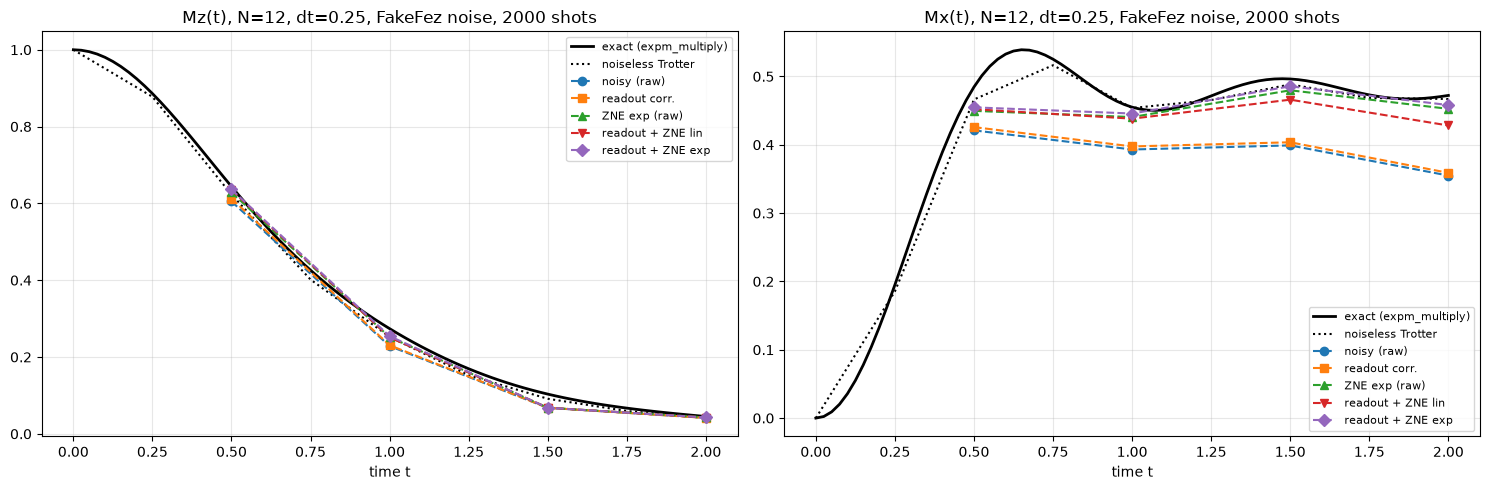

In [13]:
# [cell 12] Plots: exact, noiseless Trotter, noisy and mitigated curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (name, ci) in zip(axes, (("Mz", 0), ("Mx", 1))):
    ax.plot(t_fine, ex_fine[:, ci], "k-", lw=2, label="exact (expm_multiply)")
    ax.plot(t_k, (tr1 if name == "Mz" else tr2)[:, ci], "k:", label="noiseless Trotter")
    for lab, mk in zip(methods, ["o--", "s--", "^--", "v--", "D--"]):
        ax.plot(DT * np.array(KS), methods[lab][name], mk, label=lab)
    ax.set_xlabel("time t"); ax.set_title(f"{name}(t), N={N}, dt={DT}, FakeFez noise, {SHOTS} shots")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

              method | Mz mean|err|   Mz max | Mx mean|err|   Mx max
         noisy (raw) |       0.0308   0.0454 |       0.0850   0.1173
       readout corr. |       0.0285   0.0432 |       0.0805   0.1133
       ZNE exp (raw) |       0.0188   0.0356 |       0.0214   0.0350
   readout + ZNE lin |       0.0175   0.0355 |       0.0309   0.0440
   readout + ZNE exp |       0.0164   0.0355 |       0.0160   0.0298
   noiseless Trotter |       0.0146   0.0213 |       0.0082   0.0183


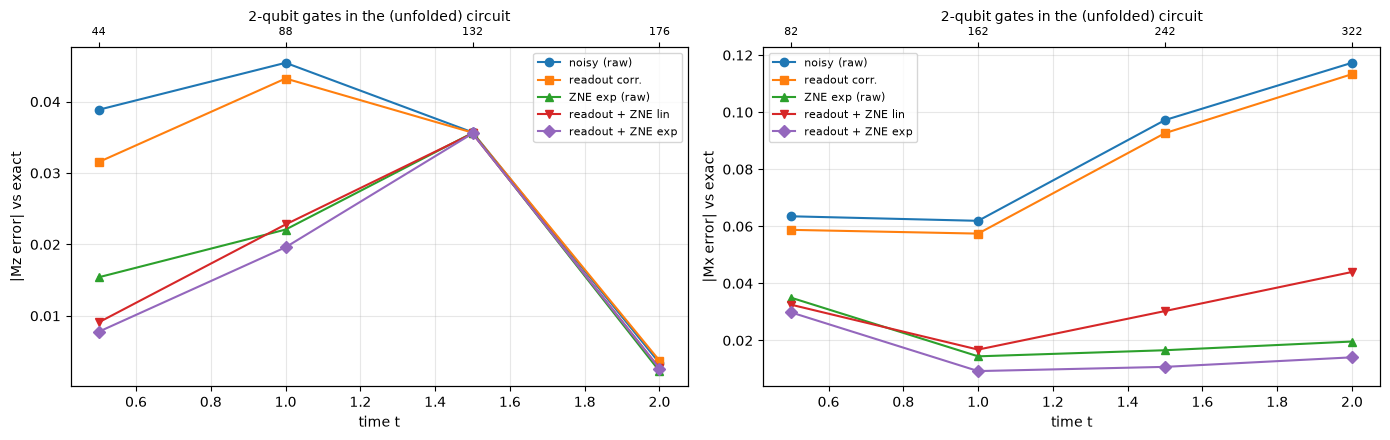


Markdown table for the README (mean |error| over the noisy time points):
| Method | Mz mean err | Mx mean err |
|---|---|---|
| noisy (raw) | 0.0308 | 0.0850 |
| readout corr. | 0.0285 | 0.0805 |
| ZNE exp (raw) | 0.0188 | 0.0214 |
| readout + ZNE lin | 0.0175 | 0.0309 |
| readout + ZNE exp | 0.0164 | 0.0160 |
| noiseless Trotter (no noise) | 0.0146 | 0.0082 |

Circuit sizes (2q gates, depth), scale 1: {('Z', 2): (44, 97), ('Z', 4): (88, 130), ('Z', 6): (132, 162), ('Z', 8): (176, 194), ('X', 2): (82, 289), ('X', 4): (162, 557), ('X', 6): (242, 825), ('X', 8): (322, 1093)}


In [14]:
# [cell 13] Errors vs exact: table, and error vs time / circuit size
ex_at_k = {"Mz": ex_k[KS, 0], "Mx": ex_k[KS, 1]}
print(f"{'method':>20} | {'Mz mean|err|':>12} {'Mz max':>8} | {'Mx mean|err|':>12} {'Mx max':>8}")
errs = {}
for lab in methods:
    row = []
    for name in ("Mz", "Mx"):
        e = np.abs(methods[lab][name] - ex_at_k[name]); errs[(lab, name)] = e
        row += [e.mean(), e.max()]
    print(f"{lab:>20} | {row[0]:>12.4f} {row[1]:>8.4f} | {row[2]:>12.4f} {row[3]:>8.4f}")
ref = [np.abs((tr1 if n == 'Mz' else tr2)[KS, i] - ex_at_k[n]) for i, n in enumerate(("Mz", "Mx"))]
print(f"{'noiseless Trotter':>20} | {ref[0].mean():>12.4f} {ref[0].max():>8.4f} | {ref[1].mean():>12.4f} {ref[1].max():>8.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, ("Mz", "Mx")):
    for lab, mk in zip(methods, ["o-", "s-", "^-", "v-", "D-"]):
        ax.plot(DT * np.array(KS), errs[(lab, name)], mk, label=lab)
    ax2 = ax.twiny(); ax2.set_xlim(ax.get_xlim())
    ax2.set_xticks(DT * np.array(KS))
    ax2.set_xticklabels([str(tstats[(OBS[name], k, 1)][0]) for k in KS], fontsize=8)
    ax2.set_xlabel("2-qubit gates in the (unfolded) circuit")
    ax.set_xlabel("time t"); ax.set_ylabel(f"|{name} error| vs exact"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("\nMarkdown table for the README (mean |error| over the noisy time points):")
print("| Method | Mz mean err | Mx mean err |\n|---|---|---|")
for lab in methods:
    print(f"| {lab} | {errs[(lab,'Mz')].mean():.4f} | {errs[(lab,'Mx')].mean():.4f} |")
print(f"| noiseless Trotter (no noise) | {ref[0].mean():.4f} | {ref[1].mean():.4f} |")
print("\nCircuit sizes (2q gates, depth), scale 1:",
      {(b, k): tstats[(b, k, 1)] for b in "ZX" for k in KS})